In [4]:
%load_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from pathlib import Path
import jax
import jax.numpy as jnp
from flax.training import checkpoints
from flax import serialization
from agents.a2c_rnn_flax import A2CRNNFlax, init_network_and_params
from environments.components.train_state import create_train_state
from environments.treadmill_env_jax import treadmill_session_default_params
import matplotlib.pyplot as plt
from nb_analysis_tools import load_trajectory_data, parse_behavioral_data
from aux_funcs import format_plot, format_pc_plot
import numpy as np
from sklearn.decomposition import PCA
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
from copy import copy
from nb_dynamics_plotting import *

plt.rcParams['font.family'] = 'Helvetica Light'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# --- CONFIGURATION ---
CHECKPOINT_PATH = "../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net0/step_00/checkpoint_2975"  # path to directory with checkpoint
HIDDEN_SIZE = 64
ACTION_SIZE = 2
OBS_SIZE = 4
RNN_TYPE = "GRU"
UNIT_NOISE_STD = 1e-2
LEARNING_RATE = 0
SEED = 0
NUM_ENVS = 1

# Configuration
CONFIG = {
    'hidden_size': 64,
    'action_size': 2,
    'obs_size': 4,
    'rnn_type': 'GRU',  # or 'VANILLA'
    'unit_noise_std': 0.0,
}

# Define input context
# Input format: [obs(4), prev_action_onehot(2), prev_reward(1)]
input_dim = CONFIG['obs_size'] + CONFIG['action_size'] + 1

In [6]:
# --- INITIALIZE NETWORK + TRAIN STATE ---
rng_key = jax.random.key(SEED)
net_init_key, rng_key = jax.random.split(rng_key)

network, params = init_network_and_params(
    hidden_size=HIDDEN_SIZE,
    action_size=ACTION_SIZE,
    obs_size=OBS_SIZE,
    rnn_type=RNN_TYPE,
    unit_noise_std=UNIT_NOISE_STD,
    rng_key=net_init_key,
)

train_state = create_train_state(
    rng_key=rng_key,
    obs_size=OBS_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_envs=NUM_ENVS,
    learning_rate=LEARNING_RATE,
    params=params,
)

# --- LOAD CHECKPOINT ---
print(f"Loading checkpoint from {CHECKPOINT_PATH} ...")
ckpt_path = Path(CHECKPOINT_PATH).resolve()

restored = checkpoints.restore_checkpoint(ckpt_dir=ckpt_path, target=train_state)
params = restored.params
train_state = restored
print("Model loaded successfully!")

# --- PROBE WEIGHTS ---
flat_params = jax.tree_util.tree_map(lambda x: x.shape, train_state.params)
print("Parameter shapes:")
print(flat_params)

try:
    print("Actor dense kernel sample:")
    print(train_state.params['actor_dense']['kernel'][:3, :3])
except KeyError:
    print("Could not find 'actor_dense' in params; inspect `flat_params` keys to locate structure.")

Loading checkpoint from ../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net0/step_00/checkpoint_2975 ...
Model loaded successfully!
Parameter shapes:
{'params': {'actor': {'bias': (2,), 'kernel': (64, 2)}, 'critic': {'bias': (1,), 'kernel': (64, 1)}, 'env_quality_prediction': {'bias': (3,), 'kernel': (64, 3)}, 'exp_filtered_reward_rate_prediction': {'bias': (1,), 'kernel': (64, 1)}, 'obs_pred_layer_1': {'bias': (16,), 'kernel': (64, 16)}, 'obs_prediction': {'bias': (5,), 'kernel': (16, 5)}, 'rnn_actor': {'hn': {'bias': (64,), 'kernel': (64, 64)}, 'hr': {'kernel': (64, 64)}, 'hz': {'kernel': (64, 64)}, 'in': {'bias': (64,), 'kernel': (7, 64)}, 'ir': {'bias': (64,), 'kernel': (7, 64)}, 'iz': {'bias': (64,), 'kernel': (7, 64)}}, 'rnn_critic': {'hn': {'bias': (64,), 'kernel': (64, 64)}, 'hr': {'kernel': (64, 64)}, 'hz': {'kernel': (64, 64)}, 'in': {'bias': (64,), 'kernel': (7, 64)}, 'ir': {'bias': (64,), 'kernel': (7, 64)}, 'iz': {'bias': (64,), 'kernel': (7, 64)}}}}
Ac

In [7]:
REWARD_RATE_THRESHOLD = 0.065

STRUCTURE_EVO_NETWORKS = [
    '../../../results/structure_evo_exp_gru_initial_prob_offset_full_net0/step_00/traj_002975.pkl',
    '../../../results/structure_evo_exp_gru_initial_prob_offset_full_net1/step_00/traj_002975.pkl',
    '../../../results/structure_evo_exp_gru_initial_prob_offset_full_net2/step_00/traj_002975.pkl',
    '../../../results/structure_evo_exp_gru_initial_prob_offset_full_net3/step_00/traj_002975.pkl',
    '../../../results/structure_evo_exp_gru_initial_prob_offset_full_net4/step_00/traj_002975.pkl',
    '../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001975.pkl',
]

STRUCTURE_EVO_CHECKPOINTS = [
    '../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net0/step_00/checkpoint_2975',
    '../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net1/step_00/checkpoint_2975',
    '../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net2/step_00/checkpoint_2975',
    '../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net3/step_00/checkpoint_2975',
    '../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_full_net4/step_00/checkpoint_2975',
    '../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/checkpoint_1975',
]


IndexError: index -1 is out of bounds for axis 0 with size 0

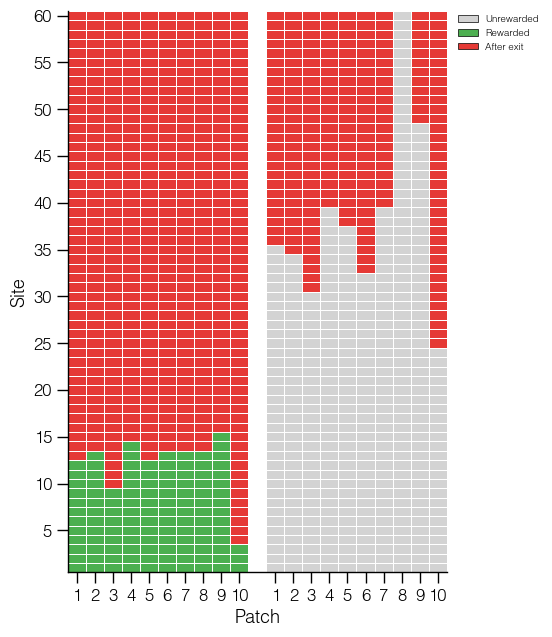

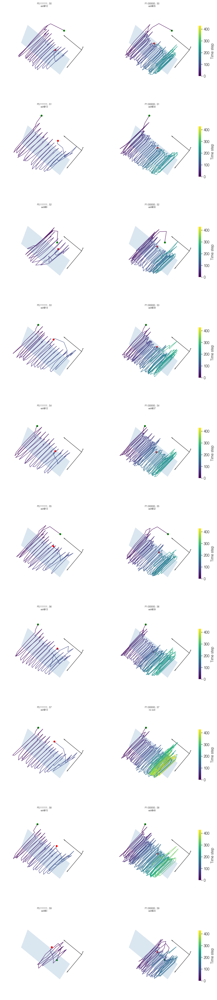

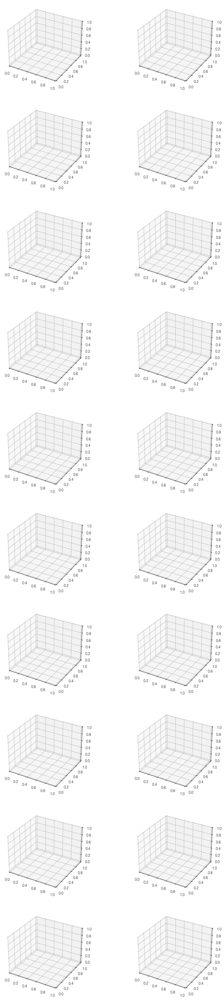

In [15]:
# PCA trajectories for two extreme reward patterns
net_idx  = 0
dir_path = STRUCTURE_EVO_NETWORKS[net_idx]
ckpt_path = STRUCTURE_EVO_CHECKPOINTS[net_idx]
n_sites  = 60

traj_data = {}
for env_idx in range(1):
    traj_data_raw = load_trajectory_data(dir_path)
    traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in traj_data_env.keys():
        if key in traj_data:
            traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
        else:
            traj_data[key] = traj_data_env[key]

pca = PCA(n_components=3)
pca.fit(traj_data['actor_hidden'].reshape(-1, 64))

tte_data = collect_pre_odor_time_to_exit(traj_data)
if tte_data['time_to_exit'].size == 0:
    tte_data = None

reward_patterns_X = [
    [1] * n_sites,   # all rewarded
    [0] * n_sites,   # never rewarded
]

for odor_off in [1, 2, 3]:
    fig_matrix, fig_pca, fig_pca_pp, fig_pp, fig_sep, fig_exit_stats, fig_obs, fig_tte, exit_sites = run_specified_reward_patterns_pca(
        reward_patterns_X,
        ckpt_path=ckpt_path,
        train_state=train_state,
        network=network,
        traj_data=traj_data,
        pca=pca,
        tte_data=tte_data,
        odor_idx=3, odor_offset=2, odor_on=6, odor_off=odor_off,
        n_stay_threshold=3,
        n_initial_states=10,
        azim=130,
        elev=80,
        seed=2,
    )

    print('Exit sites:', exit_sites)
    plt.show(fig_matrix)
    plt.close(fig_matrix)
    plt.show(fig_pca)
    plt.close(fig_pca)
    if fig_pca_pp is not None:
        plt.show(fig_pca_pp)
        plt.close(fig_pca_pp)
    plt.show(fig_pp)
    plt.close(fig_pp)
    plt.show(fig_sep)
    plt.close(fig_sep)
    plt.show(fig_exit_stats)
    plt.close(fig_exit_stats)
    plt.show(fig_obs)
    plt.close(fig_obs)
    if fig_tte is not None:
        plt.show(fig_tte)
        plt.close(fig_tte)


### Assessing strategy in network trained on fixed odor, probability offset setting

Network 0 ../../../results/structure_evo_exp_gru_initial_prob_offset_full_net0/step_00/traj_002975.pkl


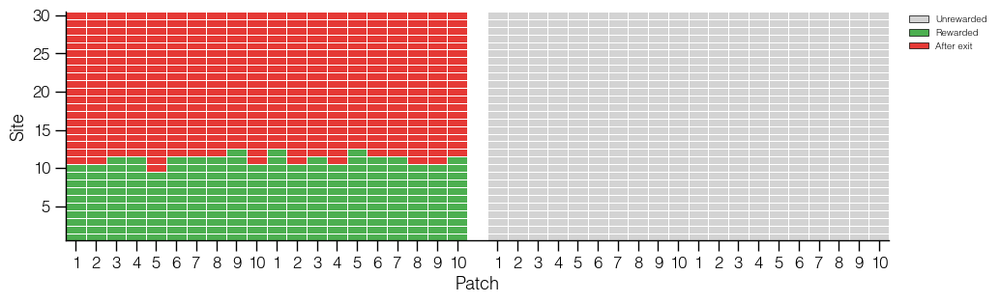

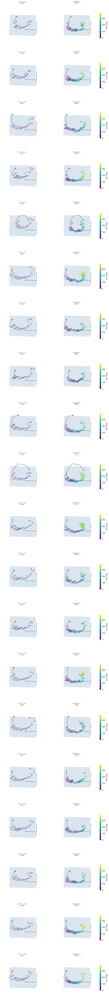

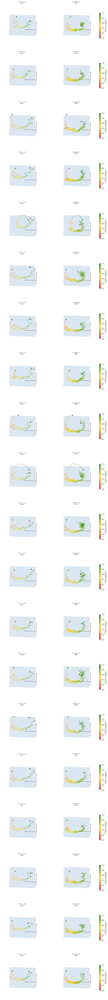

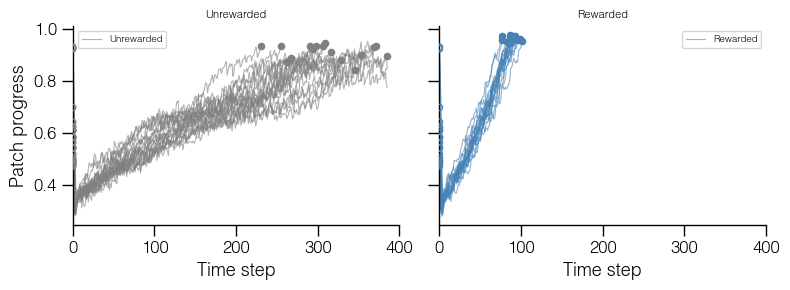

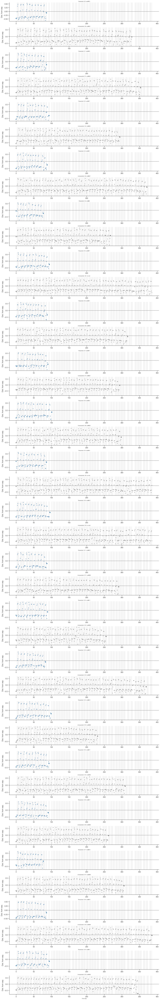

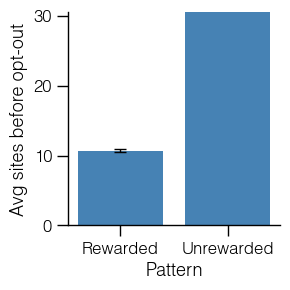

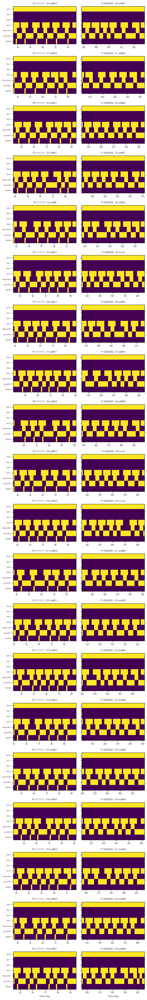

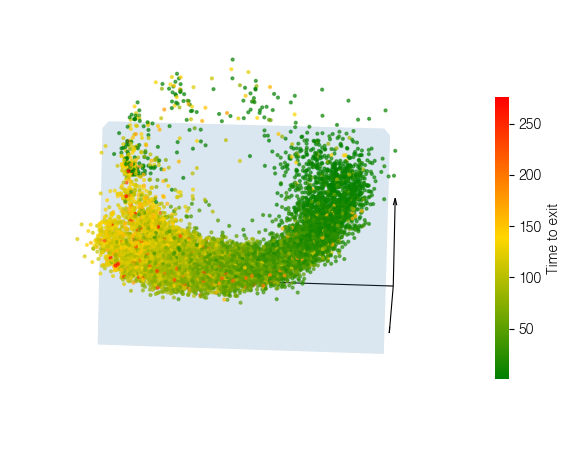

Network 1 ../../../results/structure_evo_exp_gru_initial_prob_offset_full_net1/step_00/traj_002975.pkl


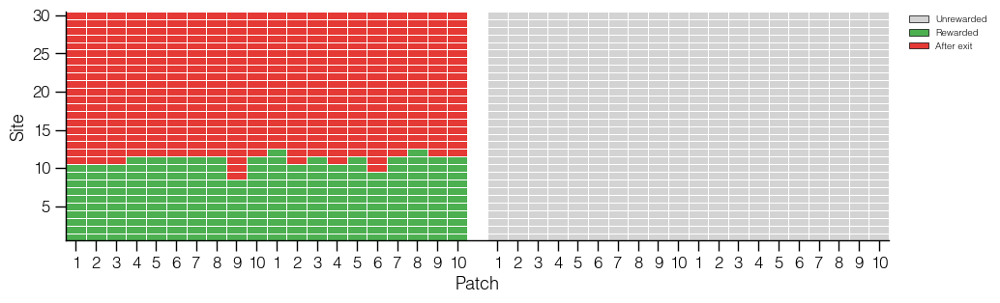

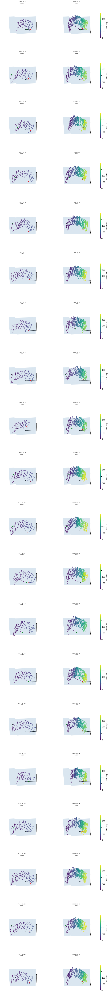

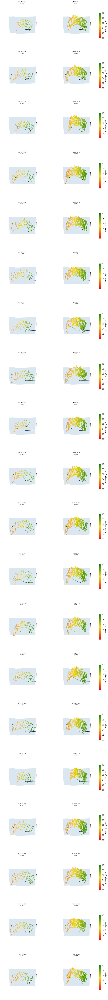

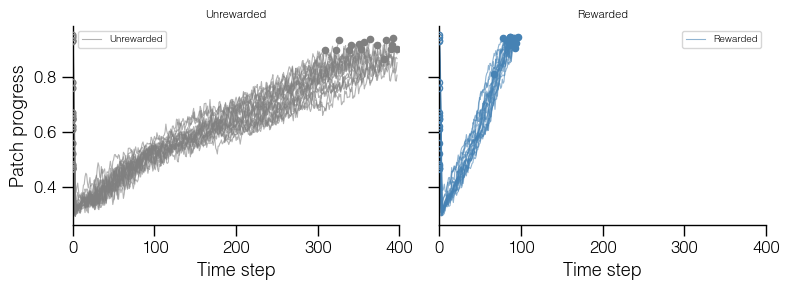

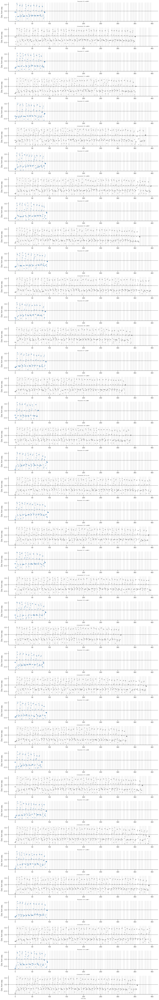

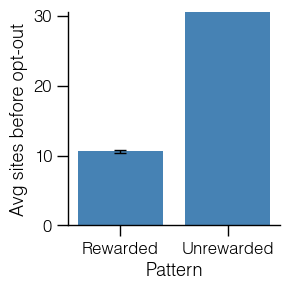

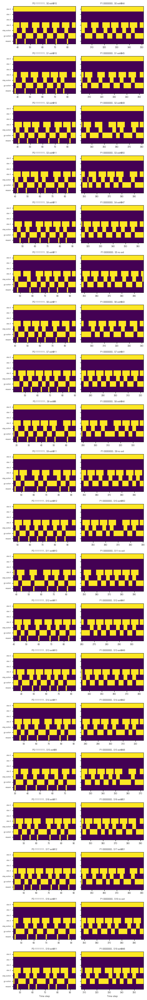

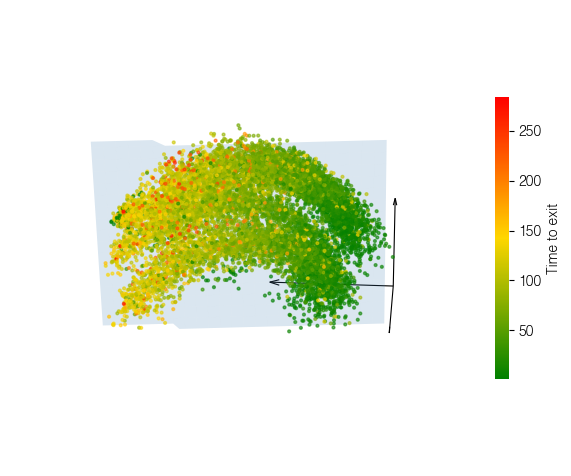

Network 2 ../../../results/structure_evo_exp_gru_initial_prob_offset_full_net2/step_00/traj_002975.pkl


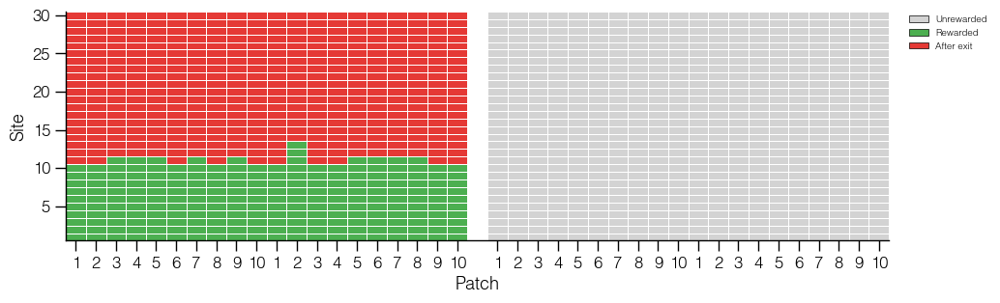

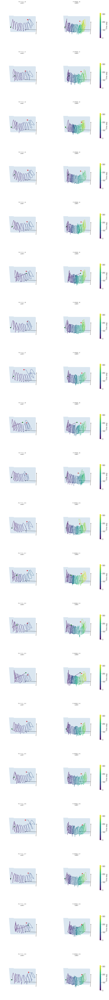

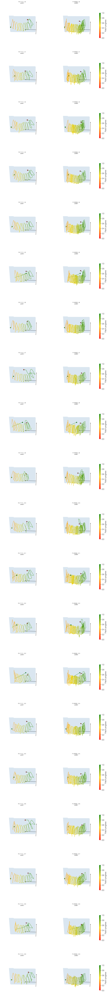

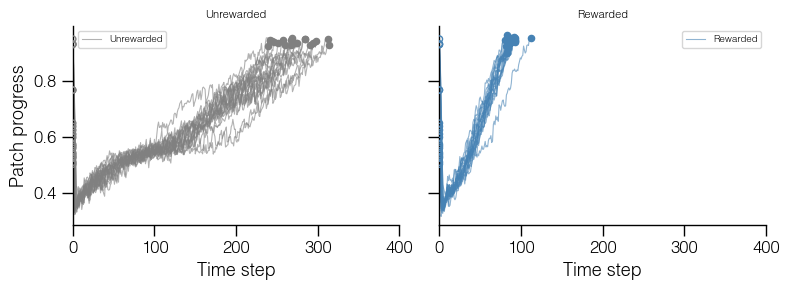

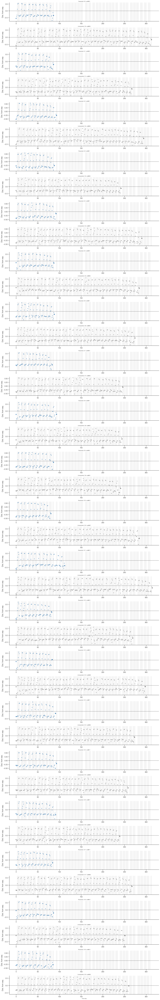

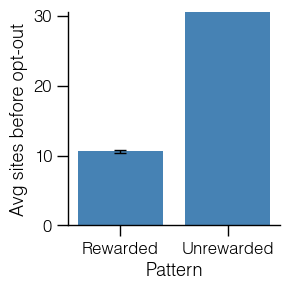

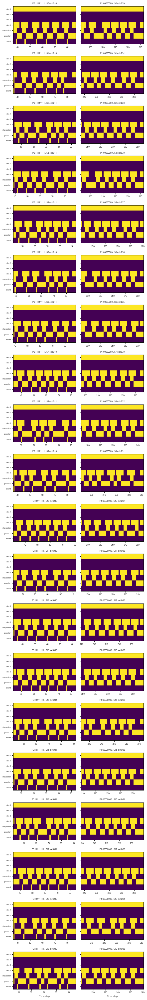

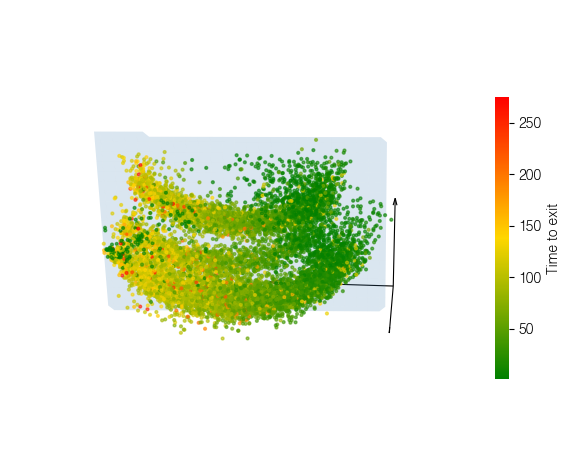

Network 3 ../../../results/structure_evo_exp_gru_initial_prob_offset_full_net3/step_00/traj_002975.pkl


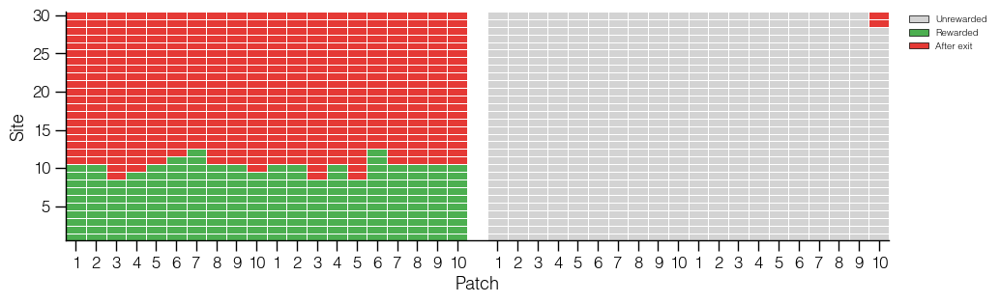

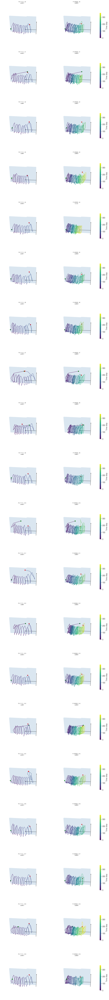

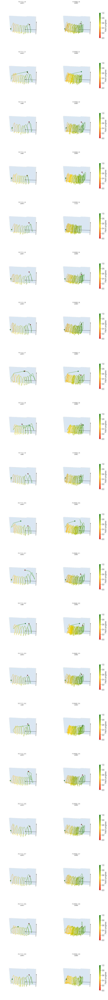

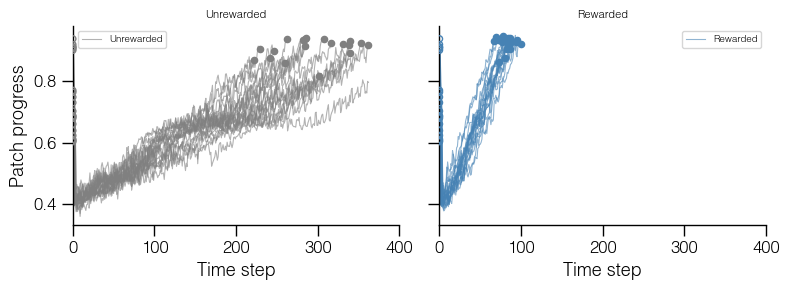

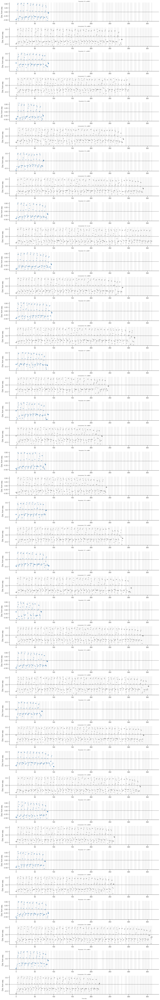

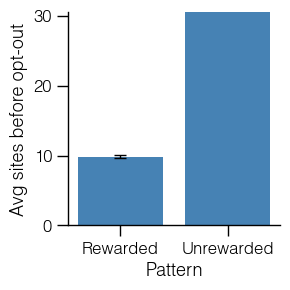

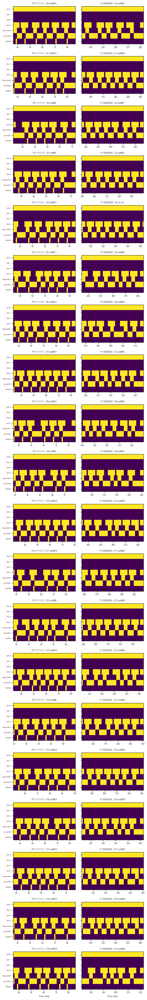

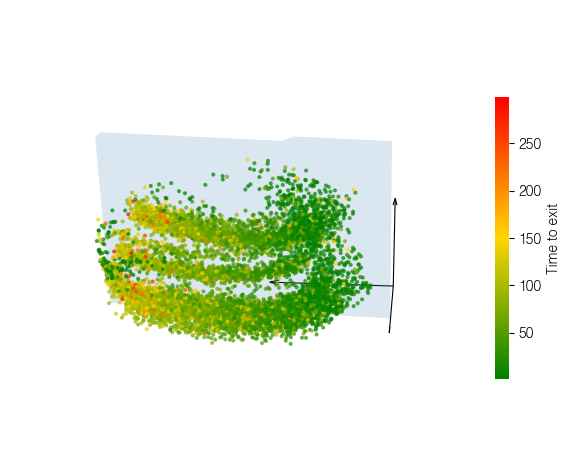

Network 4 ../../../results/structure_evo_exp_gru_initial_prob_offset_full_net4/step_00/traj_002975.pkl


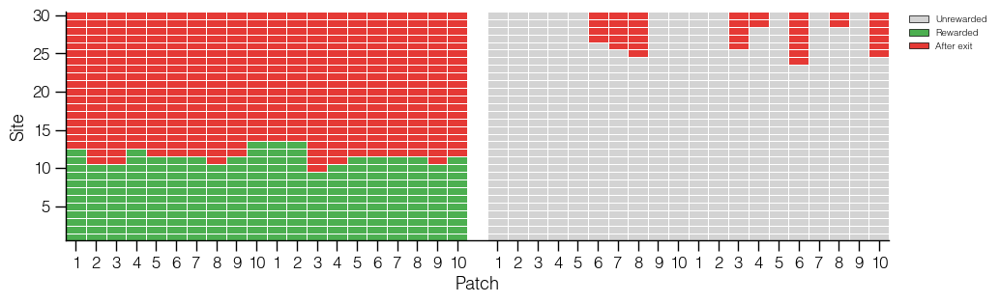

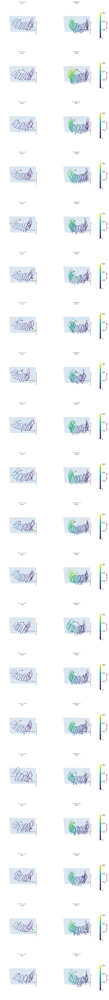

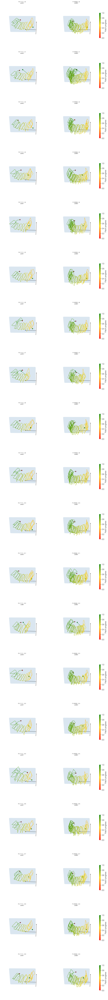

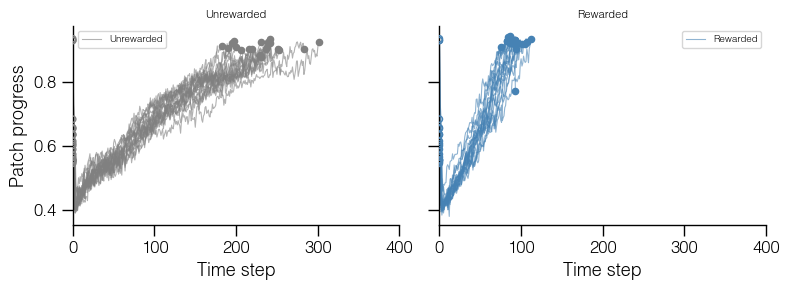

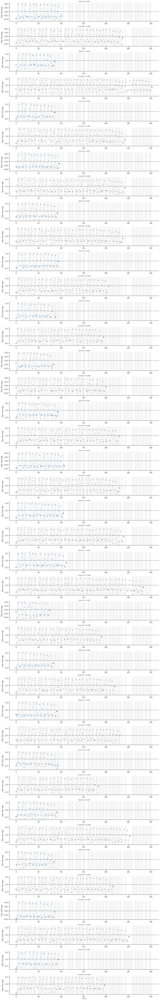

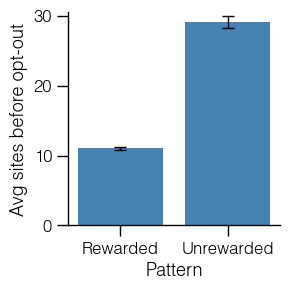

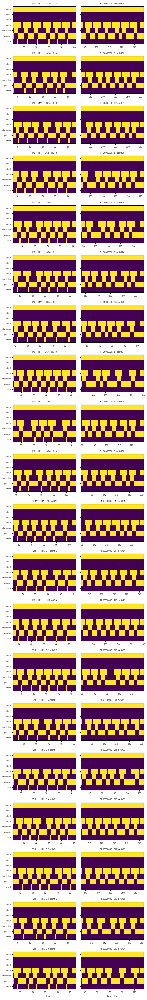

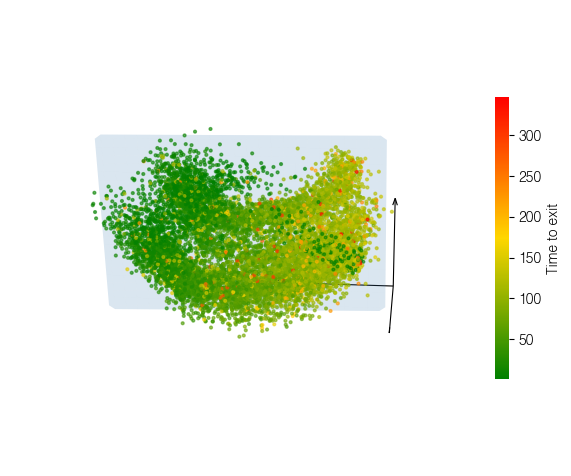

Network 5 ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001975.pkl


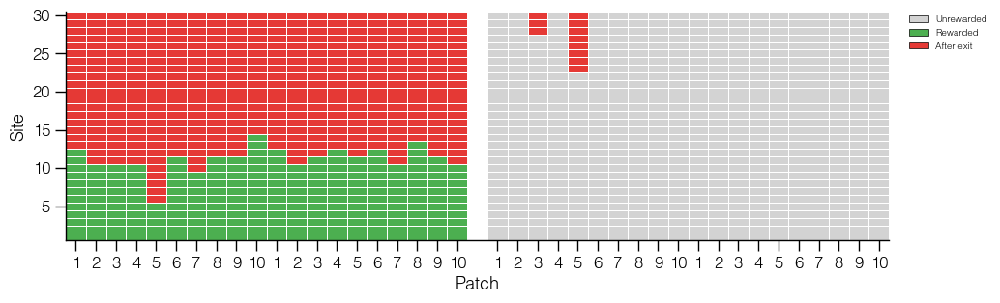

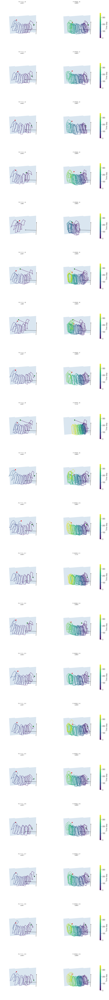

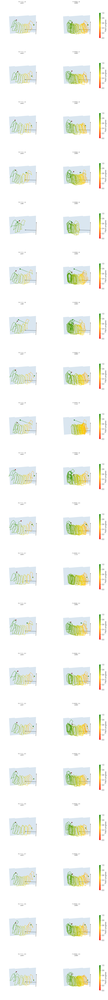

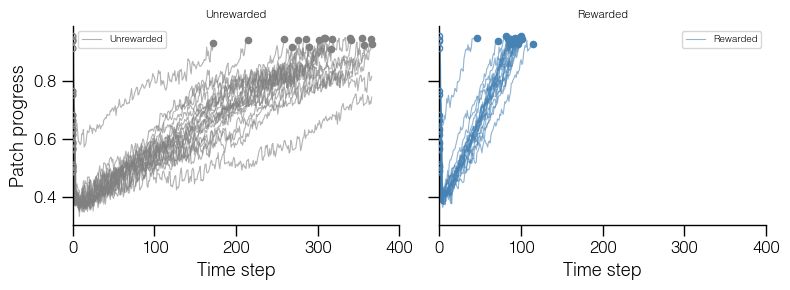

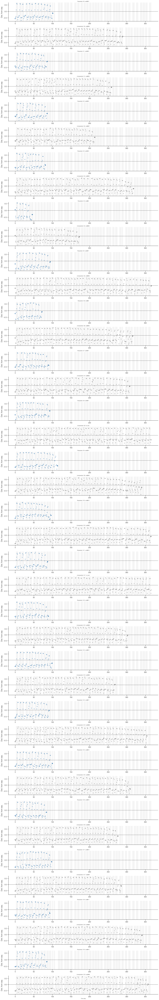

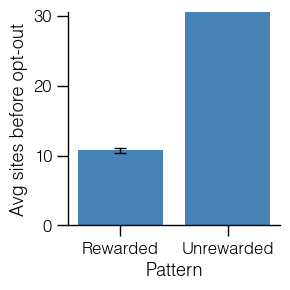

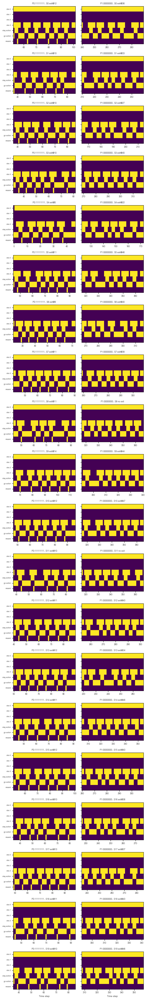

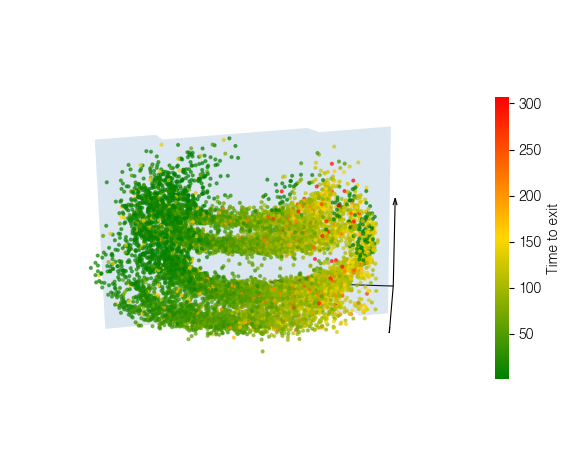

In [11]:
# PCA trajectories for two extreme reward patterns (environment rollout)
for net_idx in range(len(STRUCTURE_EVO_NETWORKS)):
    # if net_idx != 0:
    #     continue
    dir_path = STRUCTURE_EVO_NETWORKS[net_idx]
    ckpt_path = STRUCTURE_EVO_CHECKPOINTS[net_idx]
    n_sites  = 30

    print(f'Network {net_idx}', dir_path)

    traj_data = {}
    for env_idx in range(1):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA(n_components=3)
    pca.fit(traj_data['actor_hidden'].reshape(-1, 64))

    tte_data = collect_pre_odor_time_to_exit(traj_data, patch_num=2, include_all_patch_states=True)
    if tte_data['time_to_exit'].size == 0:
        tte_data = None

    reward_patterns_X = [
        [1] * n_sites,   # all rewarded
        [0] * n_sites,   # never rewarded
    ]

    # Same reward patterns, driven through the real environment
    (fig_matrix, fig_pca, fig_pca_pp, fig_pp, fig_sep,
     fig_exit_stats, fig_obs, fig_tte, exit_sites) = run_specified_reward_patterns_env_pca(
        reward_patterns_X,
        ckpt_path=ckpt_path,
        train_state=train_state,
        network=network,
        traj_data=traj_data,
        pca=pca,
        tte_data=tte_data,
        n_initial_states=20,
        patch_num=2,
        max_steps=400,
        azim=95,
        elev=20,
        seed=20,
    )

    plt.show(fig_matrix)
    plt.close(fig_matrix)
    plt.show(fig_pca)
    plt.close(fig_pca)
    if fig_pca_pp is not None:
        plt.show(fig_pca_pp)
        plt.close(fig_pca_pp)
    plt.show(fig_pp)
    plt.close(fig_pp)
    plt.show(fig_sep)
    plt.close(fig_sep)
    plt.show(fig_exit_stats)
    plt.close(fig_exit_stats)
    plt.show(fig_obs)
    plt.close(fig_obs)
    if fig_tte is not None:
        plt.show(fig_tte)
        plt.close(fig_tte)


Net 0: 0 pre-odor reference states.
  195 patch visits ≥ 20 steps found.


IndexError: index -1 is out of bounds for axis 0 with size 0

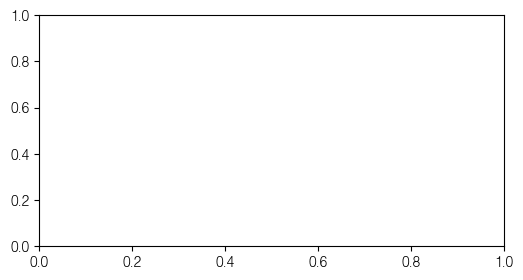

In [13]:
N_PATCHES_TO_PLOT = 20   # real patch visits to overlay per network
N_ENVS_TO_LOAD   = 1    # env rollouts to pool (more = better tte_data coverage)
MIN_PATCH_LEN     = 20   # skip very short patches (likely truncated at rollout boundary)
ODOR_IDX_PP       = 3    # odor channel to shade (matches the network's primary odor input)

for net_idx in range(len(STRUCTURE_EVO_NETWORKS)):
    dir_path = STRUCTURE_EVO_NETWORKS[net_idx]
    # dir_path = STRUCTURE_EVO_NETWORKS[net_idx]

    # ── Load real rollout data ────────────────────────────────────────────────
    traj_data = {}
    for env_idx in range(N_ENVS_TO_LOAD):
        raw = load_trajectory_data(dir_path)
        env = parse_behavioral_data(raw[env_idx])
        for key, val in env.items():
            traj_data[key] = np.concatenate([traj_data[key], val]) if key in traj_data else val

    # Build the kNN reference set: pre-odor hidden states paired with the number
    # of steps remaining until the agent left the patch.  patch_progress() maps
    # any hidden state to 1 - (predicted_tte / p98_tte), giving a scalar in [0, 1]
    # where 0 = just entered, 1 = about to leave.
    tte_data = collect_pre_odor_time_to_exit(traj_data, patch_num=2)
    if tte_data['time_to_exit'].size == 0:
        tte_data = None
    print(f"Net {net_idx}: {len(tte_data['hidden'])} pre-odor reference states.")

    # ── Find all patch visits in the rollout ──────────────────────────────────
    N_STEPS  = 20000
    n_envs   = traj_data['observations'].shape[0] // N_STEPS
    obs_rs     = traj_data['observations'].reshape(n_envs, N_STEPS, -1).transpose(1, 0, 2)
    hidden_rs  = traj_data['actor_hidden'].reshape(n_envs, N_STEPS, -1).transpose(1, 0, 2)
    rewards_rs = traj_data['rewards_seen_in_patch'].reshape(n_envs, N_STEPS).T  # (T, n_envs)
    in_patch   = obs_rs[:, :, 0] > 0.5   # (T, n_envs)

    periods = extract_patch_starts_and_stops(in_patch)  # list[n_envs] of (n_patches, 2)

    all_patches = []
    for trial_idx, trial_periods in enumerate(periods):
        for start, end in trial_periods:
            if end - start < MIN_PATCH_LEN:
                continue
            odor = obs_rs[start:end, trial_idx, ODOR_IDX_PP]
            onsets = np.sum(np.diff((odor > 0.5).astype(int)) == 1)
            if odor[0] > 0.5:
                onsets += 1
            all_patches.append({
                'hidden': hidden_rs[start:end, trial_idx],
                'odor':   odor,
                'rewards_total': float(rewards_rs[end - 2, trial_idx]),
                'sites_visited': int(onsets),
            })

    print(f"  {len(all_patches)} patch visits ≥ {MIN_PATCH_LEN} steps found.")

    if tte_data is not None:
        # Randomly sample a subset to plot
        rng    = np.random.default_rng(42)
        chosen = rng.choice(len(all_patches),
                            size=min(N_PATCHES_TO_PLOT, len(all_patches)),
                            replace=False)

        # ── Plot patch progress vs time step ──────────────────────────────────────
        fig, ax = plt.subplots(figsize=(6, 3))
        cmap = plt.cm.viridis
        norm = Normalize(vmin=0, vmax=len(chosen) - 1)

        for plot_i, patch_i in enumerate(chosen):
            patch = all_patches[patch_i]
            h     = patch['hidden']   # (T, 64)
            odor  = patch['odor']     # (T,)
            pp    = patch_progress(h, tte_data, n_neighbors=100)   # (T,) in [0, 1]
            ts    = np.arange(len(pp))
            color = cmap(norm(plot_i))

            # Shade timesteps where the odor channel is active
            odor_on = odor > 0.5
            trans   = np.diff(odor_on.astype(int), prepend=0, append=0)
            for t_s, t_e in zip(np.where(trans == 1)[0], np.where(trans == -1)[0]):
                ax.axvspan(t_s, t_e, alpha=0.06, color='grey', linewidth=0, zorder=0)

            ax.plot(ts, pp, color=color, linewidth=0.8, alpha=0.7)
            ax.scatter(ts[0],  pp[0],  facecolors='none', edgecolors=color,
                       s=16, linewidths=1.0, zorder=4)
            ax.scatter(ts[-1], pp[-1], color=color, s=16, zorder=4)

        ax.set_xlabel('Time step within patch', fontsize=9)
        ax.set_ylabel('Patch progress', fontsize=9)
        ax.set_ylim(-0.05, 1.05)
        ax.set_title(f'Network {net_idx} — {len(chosen)} real patch visits', fontsize=9)
        format_plot(ax)
        plt.tight_layout()
        plt.show()
        plt.close(fig)

        # ── Rewards collected vs sites stayed ─────────────────────────────────────
        sites_arr   = np.array([p['sites_visited']  for p in all_patches])
        rewards_arr = np.array([p['rewards_total']  for p in all_patches])

        fig_rvc, ax_rvc = plt.subplots(figsize=(5, 4))
        ax_rvc.scatter(sites_arr, rewards_arr, s=15, alpha=0.4, color='steelblue',
                       edgecolors='none')
        ax_rvc.set_xlabel('Sites stayed', fontsize=9)
        ax_rvc.set_ylabel('Rewards collected', fontsize=9)
        ax_rvc.set_title(f'Network {net_idx} — {len(all_patches)} real patches', fontsize=9)
        format_plot(ax_rvc)
        fig_rvc.tight_layout()
        plt.show(fig_rvc)
        plt.close(fig_rvc)
